# 12 · Home/Office: tính theo thời gian trong khung giờ, và chọn khung giờ nào

Classifier v1 (`HeuristicClassifier`) hiện gán nhãn mỗi stay-point theo **giờ đến** (giờ địa phương, notebook 09): đến trong 22–06 h là "home", đến trong 09–18 h ngày thường là "office". Một người về nhà lúc 20:00 rồi ngủ ở đó thì không bao giờ được tính là "home". Hai khung 22–06 / 09–18 cũng chỉ là giá trị đặt tạm, chưa có bằng chứng.

**Câu hỏi:**
1. Tính theo **số phút của stay nằm trong khung giờ** có tốt hơn tính theo giờ đến không?
2. Khung giờ home/office nên là giờ nào? Dữ liệu nói gì về giờ người dùng ở nhà và ở chỗ làm?
3. Kết quả có nhạy với mép khung không?

**Ràng buộc đã chốt:** v1 theo đúng spec trong README, tức là **xét từng stay-point riêng lẻ, không gộp**. Gộp các stay gần nhau là việc của v2 (DBSCAN, task 3.5). Trong notebook này, phiên bản "gộp trong 200 m" chỉ dùng để **so sánh**: nó cho thấy v2 có thể làm được đến đâu.

**Không có nhãn home/office thật.** Vì vậy cần một mốc so sánh **không phụ thuộc mép khung đang thử**:
- **Nơi ngủ lõi** của một user là vùng 200 m (bán kính stay-point, notebook 07) có nhiều phút nhất trong **02–05 h**, phần giữa của khoảng đêm. Mọi khung home được thử đều chứa 02–05 h, nhưng mép của chúng nằm ngoài khoảng này.
- **Nơi làm lõi** là vùng 200 m có nhiều phút nhất trong **12–15 h, thứ 2–6**, phần giữa của khoảng ban ngày.

Mốc này ưu tiên những khung hẹp quanh lõi. Vì vậy mỗi khung luôn được đọc cùng **số user tìm được**, giống cách notebook 07 đặt recall cạnh số false stay.

Chỉ dùng stay-point thật do pipeline tạo ra (`data/processed/staypoints/`), giờ địa phương theo vị trí (`arrival_local`, `departure_local`). Mỗi user có trọng số bằng nhau, để user có 1.921 stay không lấn át các user khác.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

NOTEBOOK = "12_home_office_time_windows"
DATA_DIR = Path("../data/raw")
OUT_DIR = Path("outputs") / NOTEBOOK
FIG_DIR, TABLE_DIR, CACHE_DIR, MAP_DIR = (OUT_DIR / d for d in ("figures", "tables", "cache", "maps"))
for d in (FIG_DIR, TABLE_DIR, CACHE_DIR, MAP_DIR):
    d.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(Path("../src").resolve()))
STAY_DIR = Path("../data/processed/staypoints")
NEAR_M = 200                     # "cùng một nơi" = bán kính stay-point (notebook 07)
EARTH_M = 6_371_008.8
WORK_DAYS = (0, 1, 2, 3, 4)      # thứ 2–6 theo giờ địa phương; kiểm chứng ở mục 3
NIGHT_CORE = (2, 5)              # giữa khoảng đêm (mục 3)
DAY_CORE = (12, 15)              # giữa khoảng ban ngày, thứ 2–6 (mục 3)
ROLE_COLORS = {"night_place": "#2a78d6", "day_place": "#eb6834", "elsewhere": "#1baf7a"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6})

## 1. Dữ liệu: chia mỗi stay thành từng giờ địa phương
Mỗi stay `[arrival_local, departure_local)` được cắt thành các ô (ngày, giờ) cùng số phút nằm trong ô đó. Ví dụ, stay từ 20:30 đến 07:10 hôm sau cho 30 phút ở ô 20 h, 60 phút ở mỗi ô từ 21 h đến 6 h, và 10 phút ở ô 7 h. Khi đó, số phút trong **bất kỳ** khung giờ nào có mép là giờ chẵn chỉ là tổng của vài cột. Ô thuộc ngày làm việc hay cuối tuần được xét theo **ngày của chính ô đó**.

- `H_all[stay, h]`: số phút của stay trong giờ `h`, mọi ngày.
- `H_work[stay, h]`: như trên, nhưng chỉ tính các ô rơi vào thứ 2–6.

In [2]:
paths = sorted(STAY_DIR.glob("user_*.parquet"))
stays = pd.concat([pd.read_parquet(p) for p in paths], ignore_index=True)
stays["user_id"] = stays["user_id"].astype(str).str.zfill(3)


def hourly_slots(stays: pd.DataFrame) -> pd.DataFrame:
    """Một dòng cho mỗi (stay, giờ địa phương) mà stay có mặt: sid, hour_start, minutes."""
    a = stays["arrival_local"].to_numpy("datetime64[s]")
    d = stays["departure_local"].to_numpy("datetime64[s]")
    h0 = a.astype("datetime64[h]")
    n = (d.astype("datetime64[h]") - h0).astype(int) + 1
    sid = np.repeat(np.arange(len(stays)), n)
    start = h0[sid] + (np.arange(n.sum()) - np.repeat(np.cumsum(n) - n, n)).astype("timedelta64[h]")
    minutes = (np.minimum(start + np.timedelta64(1, "h"), d[sid]) - np.maximum(start, a[sid])) / np.timedelta64(1, "m")
    out = pd.DataFrame({"sid": sid, "hour_start": start, "minutes": minutes})
    out = out[out["minutes"] > 0].reset_index(drop=True)
    out["hour"] = out["hour_start"].dt.hour
    out["weekday"] = out["hour_start"].dt.dayofweek
    out["user_id"] = stays["user_id"].to_numpy()[out["sid"]]
    return out


slots = hourly_slots(stays)
H_all = np.zeros((len(stays), 24))
np.add.at(H_all, (slots["sid"].to_numpy(), slots["hour"].to_numpy()), slots["minutes"].to_numpy())
work = slots["weekday"].isin(WORK_DAYS).to_numpy()
H_work = np.zeros((len(stays), 24))
np.add.at(H_work, (slots["sid"].to_numpy()[work], slots["hour"].to_numpy()[work]), slots["minutes"].to_numpy()[work])

print(f"Stay files: {len(paths)} users; users with >= 1 stay: {stays['user_id'].nunique()}; stays: {len(stays):,}; "
      f"hour slots: {len(slots):,}")
print(f"Check: slot minutes {H_all.sum() / 60:,.1f} h vs duration_minutes {stays['duration_minutes'].sum() / 60:,.1f} h")

Stay files: 182 users; users with >= 1 stay: 174; stays: 18,597; hour slots: 97,870
Check: slot minutes 79,374.6 h vs duration_minutes 79,376.6 h


### Các hàm dùng chung
- `window_hours(start, end)`: các giờ trong khung `[start, end)`, có thể vắt qua nửa đêm (22–08 gồm 22, 23, 0, …, 7).
- `pick_stay`: **luật v1 xét từng stay**. Chọn stay có nhiều phút trong khung nhất. Nếu hoà thì chọn stay dài hơn (`duration_minutes`), nếu vẫn hoà thì chọn stay đến sớm hơn. Luật phá hoà được bàn ở mục 5.
- `pick_grouped`: **chỉ để so sánh**. Điểm của mỗi stay là tổng số phút trong khung của mọi stay cách nó ≤ 200 m, gần đúng với việc gộp stay trước khi chấm như v2.
- `confidence` = số phút của nơi thắng / tổng số phút trong khung của user, đúng định nghĩa trong README ("tỷ lệ thời gian ở tại location trong khung giờ kỳ vọng").

In [3]:
users = stays["user_id"].to_numpy()
USER_IDX = {u: np.flatnonzero(users == u) for u in pd.unique(users)}
DUR = stays["duration_minutes"].to_numpy()
ARR = stays["arrival"].to_numpy("datetime64[s]").astype(np.int64)
LAT, LON = np.radians(stays["lat"].to_numpy()), np.radians(stays["lon"].to_numpy())


def near_matrix(ix: np.ndarray) -> np.ndarray:
    la, lo = LAT[ix], LON[ix]
    h = np.sin((la[:, None] - la) / 2) ** 2 + np.cos(la[:, None]) * np.cos(la) * np.sin((lo[:, None] - lo) / 2) ** 2
    return 2 * EARTH_M * np.arcsin(np.sqrt(h)) <= NEAR_M


NEAR = {u: near_matrix(ix) for u, ix in USER_IDX.items()}


def window_hours(start: int, end: int) -> list[int]:
    return [h % 24 for h in range(start, end if end > start else end + 24)]


def window_minutes(M: np.ndarray, start: int, end: int) -> np.ndarray:
    return M[:, window_hours(start, end)].sum(axis=1)


def _best(v: np.ndarray, ix: np.ndarray) -> int | None:
    if v.max() <= 0:
        return None
    return int(np.lexsort((ARR[ix], -DUR[ix], -v))[0])     # khoá cuối là khoá chính


def pick_stay(score: np.ndarray, u: str) -> tuple[int | None, float]:
    """Luật v1: (vị trí stay thắng trong USER_IDX[u], confidence)."""
    v = score[USER_IDX[u]]
    i = _best(v, USER_IDX[u])
    return (None, np.nan) if i is None else (i, v[i] / v.sum())


def pick_grouped(score: np.ndarray, u: str) -> tuple[int | None, float]:
    """Chỉ để so sánh: chấm điểm cả vùng 200 m quanh mỗi stay."""
    v0 = score[USER_IDX[u]]
    v = NEAR[u] @ v0
    i = _best(v, USER_IDX[u])
    return (None, np.nan) if i is None else (i, v[i] / v0.sum())


def core_place(M: np.ndarray, start: int, end: int) -> dict[str, np.ndarray]:
    """Mốc so sánh: mặt nạ các stay thuộc vùng 200 m có nhiều phút nhất trong [start, end)."""
    score = window_minutes(M, start, end)
    out = {}
    for u, ix in USER_IDX.items():
        v = NEAR[u] @ score[ix]
        if v.max() > 0:
            out[u] = NEAR[u][int(v.argmax())]
    return out


def evaluate(score: np.ndarray, ref: dict, picker=pick_stay) -> dict:
    found, agree, conf = 0, [], []
    for u in USER_IDX:
        i, c = picker(score, u)
        if i is None:
            continue
        found += 1
        conf.append(c)
        if u in ref:
            agree.append(bool(ref[u][i]))
    return {"found": found, "agree": np.mean(agree), "n_ref": len(agree), "median_conf": np.median(conf)}


night_core = core_place(H_all, *NIGHT_CORE)
day_core = core_place(H_work, *DAY_CORE)
print(f"Users with a core-night place (any minute in {NIGHT_CORE[0]:02d}-{NIGHT_CORE[1]:02d} h): {len(night_core)}; "
      f"with a core-work place (Mon-Fri {DAY_CORE[0]}-{DAY_CORE[1]} h): {len(day_core)}")

Users with a core-night place (any minute in 02-05 h): 148; with a core-work place (Mon-Fri 12-15 h): 149


## 2. Vì sao luật "giờ đến" bỏ sót home
Xét các stay **có mặt lúc 03:00** (ở qua đêm). Nếu phần lớn trong số đó bắt đầu trước 22:00, thì luật giờ đến (22–06 h) bỏ sót chính những đêm ở nhà.

**Vì sao 03:00?** Đây là giờ giữa đêm, lúc hầu hết mọi người đang ngủ, nên stay có mặt lúc đó gần như chắc chắn là chỗ ngủ. Con số này **không được tinh chỉnh**. Bảng kiểm tra bên dưới lặp lại phép đếm cho mọi giờ từ 00:00 đến 06:00 để xem kết quả có phụ thuộc vào 03:00 không. Cột đậm trong hình là giờ đến nằm trong khung 22–06 của luật cũ; cột nhạt là ngoài khung đó.

Stays present at 03:00: 3,554; arriving inside 22-06 h: 44.6%; arriving 18-22 h: 44.7%
Users with a home candidate, same 22-06 h window: by arrival hour 130, by minutes inside the window 163 (of 174)
            stays_present  arrive_inside_22_06  arrive_18_22
clock_hour                                                  
00:00                3762                0.348         0.510
01:00                3754                0.393         0.480
02:00                3628                0.425         0.463
03:00                3554                0.446         0.447
04:00                3490                0.450         0.444
05:00                3463                0.465         0.439
06:00                3455                0.419         0.423


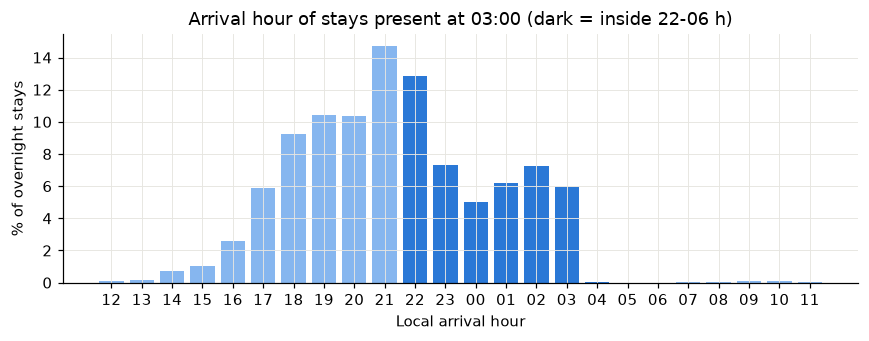

In [4]:
overnight = H_all[:, 3] > 0
arr_hour = stays["arrival_local"].dt.hour.to_numpy()
share = pd.Series(arr_hour[overnight]).value_counts(normalize=True).reindex(range(24), fill_value=0)
in_rule = (arr_hour >= 22) | (arr_hour < 6)
print(f"Stays present at 03:00: {overnight.sum():,}; arriving inside 22-06 h: {in_rule[overnight].mean():.1%}; "
      f"arriving 18-22 h: {((arr_hour >= 18) & (arr_hour < 22))[overnight].mean():.1%}")

home_arrival_users = {u for u, ix in USER_IDX.items() if in_rule[ix].any()}
home_window_users = {u for u, ix in USER_IDX.items() if window_minutes(H_all, 22, 6)[ix].max() > 0}
print(f"Users with a home candidate, same 22-06 h window: by arrival hour {len(home_arrival_users)}, "
      f"by minutes inside the window {len(home_window_users)} (of {len(USER_IDX)})")

# Vì sao 03:00? Chọn giờ giữa đêm theo suy luận; kiểm tra lại: chọn giờ khác từ 00 đến 05 thì kết quả có đổi không?
rows = []
for h in range(0, 7):
    present = H_all[:, h] > 0
    rows.append({"clock_hour": f"{h:02d}:00", "stays_present": int(present.sum()),
                 "arrive_inside_22_06": round(in_rule[present].mean(), 3),
                 "arrive_18_22": round(((arr_hour >= 18) & (arr_hour < 22))[present].mean(), 3)})
hour_check = pd.DataFrame(rows).set_index("clock_hour")
hour_check.to_csv(TABLE_DIR / "overnight_hour_check.csv")
print(hour_check.to_string())

order = list(range(12, 24)) + list(range(0, 12))
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(range(24), share.loc[order].to_numpy() * 100, color=["#2a78d6" if (h >= 22 or h < 6) else "#86b6ef" for h in order],
       width=0.8)
ax.set_xticks(range(24), [f"{h:02d}" for h in order])
ax.set_xlabel("Local arrival hour")
ax.set_ylabel("% of overnight stays")
ax.set_title("Arrival hour of stays present at 03:00 (dark = inside 22-06 h)")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig01_arrival_hour_overnight_stays.png")
plt.show()

## 3. Người dùng ở đâu theo từng giờ? (profile không dùng khung giờ nào, không bỏ user nào)
Mục tiêu là đọc khung giờ từ thói quen thật. Để khung không tự chứng minh chính nó, phần này không giả định khung nào. **Mọi user có stay đều được giữ**, kể cả user chỉ có một nơi hoặc không có dữ liệu ban đêm.

1. Với mỗi user, **nơi 1** là vùng 200 m có tổng thời gian ở lại lớn nhất (xét mọi giờ), **nơi 2** là vùng lớn nhất trong phần còn lại (cách stay trung tâm của nơi 1 > 200 m). User chỉ có một nơi thì không có nơi 2. Các stay còn lại là **nơi khác**. Bước này **không gán nhãn nhà hay cơ quan**.
2. Mỗi user được xếp vào đúng một nhóm theo việc nơi nào có nhiều phút hơn trong **02–05 h** (giờ giữa đêm, khi hầu hết mọi người đang ngủ). Đây là bước duy nhất dùng giả định "giữa đêm ngủ ở nhà":
   - `night = place 1`;
   - `night = place 2`;
   - `no minutes at 02-05 h`: không nơi nào có phút nào trong 02–05 h. Nhóm này **vẫn được vẽ**, chỉ là không có "nơi đêm" để đọc mép khung.
3. Với mỗi giờ địa phương, tách ngày thường / cuối tuần, tính tỉ lệ thời gian ở lại của user rơi vào nơi 1, nơi 2, nơi khác, rồi lấy trung bình trên các user. User không có stay vào một giờ thì không đóng góp cho giờ đó.

**Đọc mép khung:** "nơi đêm" là nơi có nhiều phút hơn lúc 02–05 h, "nơi ngày" là nơi còn lại. Đường cong của chúng chỉ có thông tin ở những chỗ **rời khỏi mức cao**; đường cao lúc 02–05 h là hệ quả của định nghĩa.

In [5]:
place = np.full(len(stays), "other", dtype=object)
group, n_places = {}, {}
for u, ix in USER_IDX.items():
    near, w = NEAR[u], DUR[ix]
    first = near[int((near @ w).argmax())]
    rest = ~first
    place[ix[first]] = "place1"
    core = H_all[ix][:, NIGHT_CORE[0]:NIGHT_CORE[1]].sum(axis=1)
    m1, m2, n_places[u] = core[first].sum(), 0.0, 1
    if rest.any():
        second = near[int(np.where(rest, (near & rest) @ w, -1).argmax())] & rest
        place[ix[second]] = "place2"
        m2, n_places[u] = core[second].sum(), 2
    group[u] = "no minutes at 02-05 h" if m1 + m2 == 0 else ("night = place 1" if m1 >= m2 else "night = place 2")

user_table = pd.DataFrame({"group": pd.Series(group), "places": pd.Series(n_places)})
user_table.to_csv(TABLE_DIR / "profile_user_groups.csv")
group_counts = user_table.groupby(["group", "places"]).size().unstack(fill_value=0)
group_counts["users"] = group_counts.sum(axis=1)
group_counts.loc["all users"] = group_counts.sum()
group_counts.to_csv(TABLE_DIR / "profile_group_counts.csv")
print(f"Users in the profile: {len(user_table)} of {len(USER_IDX)} users with a stay (none dropped)")
group_counts

Users in the profile: 174 of 174 users with a stay (none dropped)


places,1,2,users
group,,,
night = place 1,2,110,112
night = place 2,0,34,34
no minutes at 02-05 h,3,25,28
all users,5,169,174


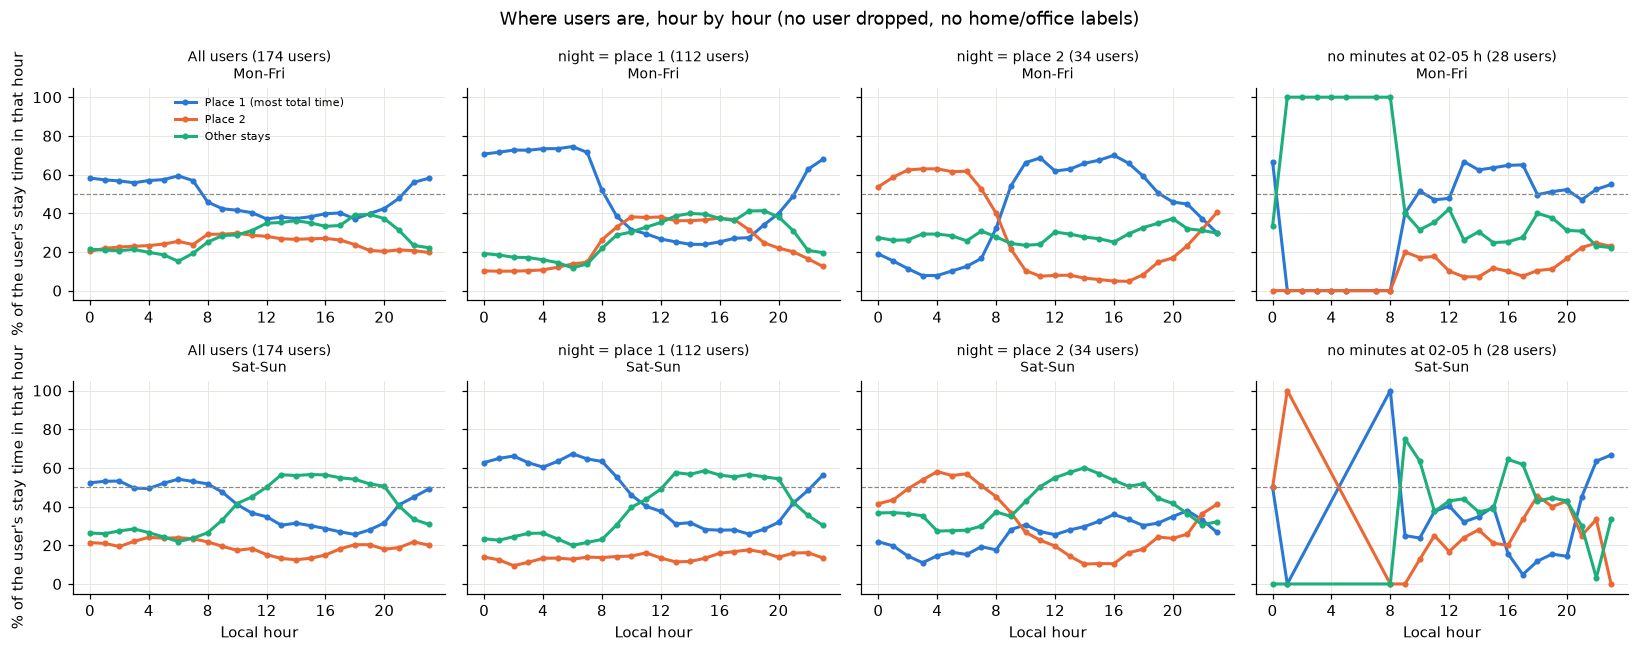

In [6]:
GROUPS = ["night = place 1", "night = place 2", "no minutes at 02-05 h"]
s = slots.assign(place=place[slots["sid"]], group=slots["user_id"].map(group),
                 daytype=np.where(slots["weekday"].isin(WORK_DAYS), "weekday", "weekend"))
per_user = s.pivot_table(index=["user_id", "group", "daytype", "hour"], columns="place", values="minutes",
                         aggfunc="sum", fill_value=0).reindex(columns=["place1", "place2", "other"], fill_value=0)
per_user = per_user.div(per_user.sum(axis=1), axis=0).reset_index()
panels = {"All users": per_user, **{g: per_user[per_user["group"] == g] for g in GROUPS}}
profile = pd.concat({name: d.groupby(["daytype", "hour"])[["place1", "place2", "other"]].mean()
                     for name, d in panels.items()}, names=["panel"])
profile.round(3).to_csv(TABLE_DIR / "hourly_profile.csv")

COLORS = {"place1": "#2a78d6", "place2": "#eb6834", "other": "#1baf7a"}
NAMES = {"place1": "Place 1 (most total time)", "place2": "Place 2", "other": "Other stays"}
fig, axes = plt.subplots(2, 4, figsize=(15, 6), sharey=True)
for col, (name, d) in enumerate(panels.items()):
    for row, daytype in enumerate(("weekday", "weekend")):
        ax = axes[row, col]
        p = profile.loc[(name, daytype)]
        for k, c in COLORS.items():
            ax.plot(p.index, p[k] * 100, color=c, linewidth=2, marker="o", markersize=3, label=NAMES[k])
        ax.axhline(50, color="#8a8980", linewidth=0.8, linestyle="--")
        ax.set_xticks(range(0, 24, 4))
        ax.set_title(f"{name} ({d['user_id'].nunique()} users)\n{'Mon-Fri' if daytype == 'weekday' else 'Sat-Sun'}",
                     fontsize=9)
        ax.set_xlabel("Local hour" if row == 1 else "")
for row in range(2):
    axes[row, 0].set_ylabel("% of the user's stay time in that hour")
axes[0, 0].legend(loc="upper center", frameon=False, fontsize=7)
fig.suptitle("Where users are, hour by hour (no user dropped, no home/office labels)")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig02_hourly_profile_by_place.png")
plt.show()

### 3.1 Mép khung từ profile
Gộp các nhóm có nơi đêm (hai nhóm đầu) lại: với mỗi user, đường **nơi đêm** là tỉ lệ thời gian ở nơi có nhiều phút hơn lúc 02–05 h; đường **nơi ngày** là tỉ lệ ở nơi còn lại (chỉ user có nơi 2). Bảng đọc ra:
- `night_place_majority`: các giờ mà nơi đêm chiếm > 50% thời gian ở lại;
- `day_place_leads`: các giờ mà nơi ngày cao hơn cả nơi đêm lẫn nơi khác.

In [7]:
def runs(hours) -> str:
    """Các giờ liên tiếp (vòng qua nửa đêm) -> '22-08 h'."""
    hs = set(hours)
    if not hs:
        return "none"
    if len(hs) == 24:
        return "all day"
    out = []
    for st in (h for h in sorted(hs) if (h - 1) % 24 not in hs):
        e = st
        while (e + 1) % 24 in hs:
            e = (e + 1) % 24
        out.append(f"{st:02d}-{(e + 1) % 24:02d} h")
    return ", ".join(out)


night_of = per_user["group"].map({"night = place 1": "place1", "night = place 2": "place2"})
day_of = per_user["group"].map({"night = place 1": "place2", "night = place 2": "place1"})
pu = per_user.assign(night_place=[r[c] if isinstance(c, str) else np.nan for c, (_, r) in zip(night_of, per_user.iterrows())],
                     day_place=[r[c] if isinstance(c, str) else np.nan for c, (_, r) in zip(day_of, per_user.iterrows())])
# nơi ngày chỉ có ở user có 2 nơi: nơi 2 không tồn tại thì tỉ lệ là 0 và không được tính là "nơi ngày"
pu.loc[pu["user_id"].map(n_places) < 2, "day_place"] = np.nan
rows = []
for daytype in ("weekday", "weekend"):
    p = pu[pu["daytype"] == daytype].groupby("hour")[["night_place", "day_place", "other"]].mean()
    leads = p[["night_place", "day_place", "other"]].idxmax(axis=1)
    rows.append({"daytype": daytype,
                 "users_with_night_place": int(pu.loc[pu["night_place"].notna(), "user_id"].nunique()),
                 "users_with_day_place": int(pu.loc[pu["day_place"].notna(), "user_id"].nunique()),
                 "night_place_majority": runs(p.index[p["night_place"] > 0.5]),
                 "day_place_leads": runs(p.index[leads == "day_place"]),
                 "day_place_max_share": round(p["day_place"].max(), 3)})
windows_from_profile = pd.DataFrame(rows).set_index("daytype")
windows_from_profile.to_csv(TABLE_DIR / "windows_from_profile.csv")
windows_from_profile

,users_with_night_place,users_with_day_place,night_place_majority,day_place_leads,day_place_max_share
daytype,,,,,
weekday,146,144,22-08 h,09-18 h,0.458
weekend,146,144,23-10 h,none,0.220


## 4. Quét khung giờ: tìm được bao nhiêu user, và có trùng nơi lõi không
Mỗi ô của lưới là một khung giờ. Có ba chỉ số:
- `found`: số user có ít nhất 1 phút trong khung;
- `agree_v1`: trong các user có mốc so sánh, tỉ lệ có **stay thắng theo luật v1** nằm trong nơi lõi;
- `agree_grouped`: như trên, nhưng chấm điểm cả vùng 200 m (chỉ để so sánh, gần với v2).

Home xét mọi ngày. Office chỉ xét thứ 2–6. Khung đang dùng (22–06, 09–18) nằm trong lưới.

In [8]:
def grid(M, starts, ends, ref):
    rows = []
    for st in starts:
        for en in ends:
            score = window_minutes(M, st, en)
            v1, gr = evaluate(score, ref), evaluate(score, ref, pick_grouped)
            rows.append({"start": st, "end": en, "found": v1["found"], "agree_v1": v1["agree"],
                         "agree_grouped": gr["agree"], "median_conf_v1": v1["median_conf"],
                         "median_conf_grouped": gr["median_conf"]})
    return pd.DataFrame(rows)


home_grid = grid(H_all, [19, 20, 21, 22, 23, 0], [5, 6, 7, 8, 9, 10], night_core)
office_grid = grid(H_work, [7, 8, 9, 10, 11], [16, 17, 18, 19, 20], day_core)
home_grid.round(3).to_csv(TABLE_DIR / "home_window_grid.csv", index=False)
office_grid.round(3).to_csv(TABLE_DIR / "office_window_grid.csv", index=False)
print(f"Home: reference users {len(night_core)}; agree_v1 range {home_grid['agree_v1'].min():.3f}-{home_grid['agree_v1'].max():.3f}, "
      f"agree_grouped range {home_grid['agree_grouped'].min():.3f}-{home_grid['agree_grouped'].max():.3f}")
print(f"Office: reference users {len(day_core)}; agree_v1 range {office_grid['agree_v1'].min():.3f}-{office_grid['agree_v1'].max():.3f}, "
      f"agree_grouped range {office_grid['agree_grouped'].min():.3f}-{office_grid['agree_grouped'].max():.3f}")

Home: reference users 148; agree_v1 range 0.622-0.716, agree_grouped range 0.784-0.912
Office: reference users 149; agree_v1 range 0.644-0.705, agree_grouped range 0.745-0.893


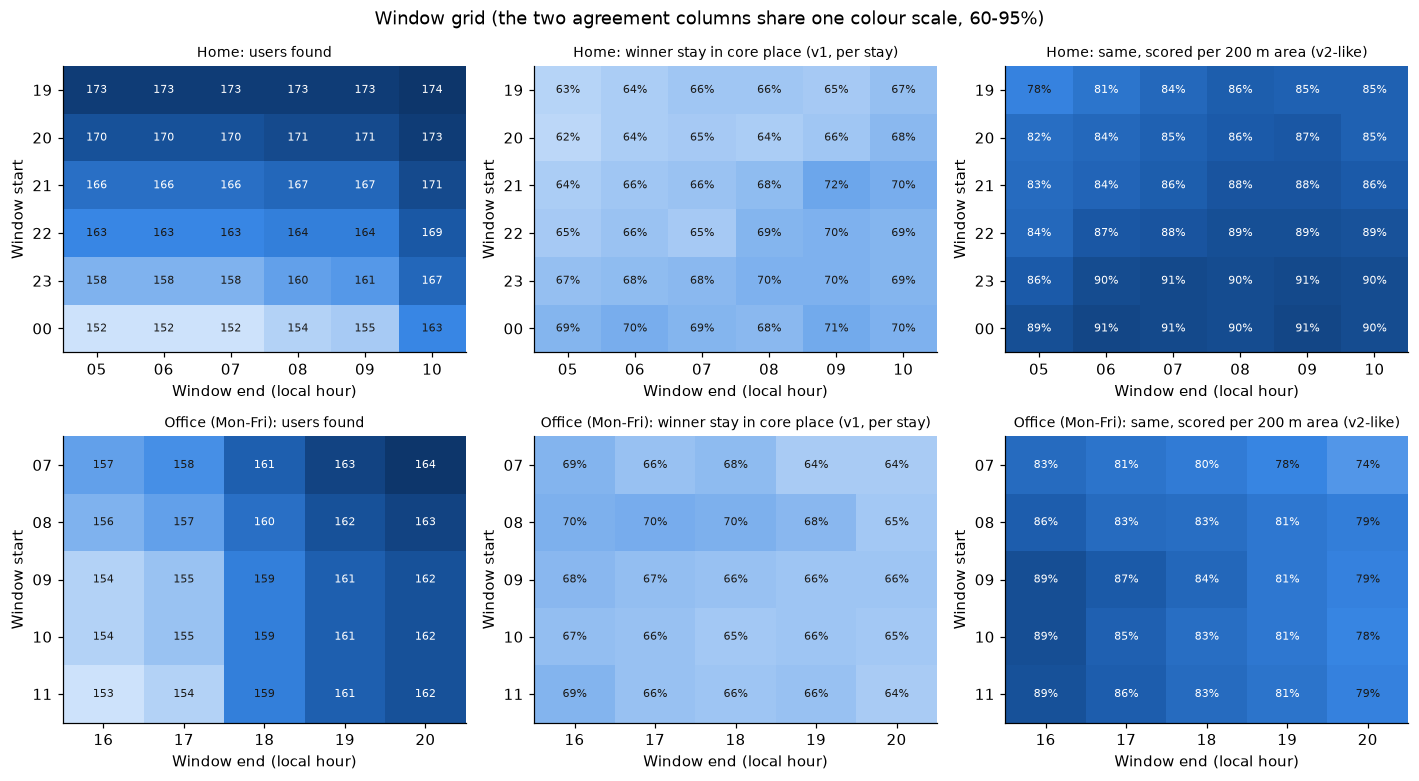

In [9]:
from matplotlib.colors import LinearSegmentedColormap

BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])


def heat(ax, g, col, title, fmt, vmin=None, vmax=None):
    t = g.pivot(index="start", columns="end", values=col).reindex(index=pd.unique(g["start"]), columns=pd.unique(g["end"]))
    lo = np.nanmin(t.to_numpy()) if vmin is None else vmin
    hi = np.nanmax(t.to_numpy()) if vmax is None else vmax
    ax.imshow(t.to_numpy(), cmap=BLUES, aspect="auto", vmin=lo, vmax=hi)
    for (r, c), v in np.ndenumerate(t.to_numpy()):
        dark = (v - lo) / (hi - lo + 1e-12) > 0.55
        ax.text(c, r, fmt(v), ha="center", va="center", fontsize=7.5, color="white" if dark else "#1a1a19")
    ax.set_xticks(range(t.shape[1]), [f"{e:02d}" for e in t.columns])
    ax.set_yticks(range(t.shape[0]), [f"{s:02d}" for s in t.index])
    ax.set_xlabel("Window end (local hour)")
    ax.set_ylabel("Window start")
    ax.set_title(title, fontsize=9)
    ax.grid(False)


fig, axes = plt.subplots(2, 3, figsize=(13, 7.2))
for row, (g, name) in enumerate([(home_grid, "Home"), (office_grid, "Office (Mon-Fri)")]):
    heat(axes[row, 0], g, "found", f"{name}: users found", lambda v: f"{v:.0f}")
    heat(axes[row, 1], g, "agree_v1", f"{name}: winner stay in core place (v1, per stay)", lambda v: f"{v:.0%}", 0.6, 0.95)
    heat(axes[row, 2], g, "agree_grouped", f"{name}: same, scored per 200 m area (v2-like)", lambda v: f"{v:.0%}", 0.6, 0.95)
fig.suptitle("Window grid (the two agreement columns share one colour scale, 60-95%)")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig03_window_grid.png")
plt.show()

## 5. Vì sao v1 (từng stay) dừng ở khoảng 2/3
Một đêm trọn vẹn đã lấp đầy cả khung, ví dụ 10 h trong khung 22–08. Vì vậy nhiều stay **hoà nhau ở mức tối đa**, và luật v1 phải chọn một trong số đó bằng luật phá hoà. Đêm ở nhà và một đêm ở khách sạn khi đi công tác có cùng số phút. Chỉ **tần suất quay lại cùng một nơi** mới phân biệt được chúng, mà tần suất thì cần gộp các stay (v2).

Phần này đếm số user bị hoà và so ba luật phá hoà: stay đến sớm nhất, stay dài nhất, stay gần đây nhất.

In [10]:
def tie_breaks(M, start, end, ref):
    score = window_minutes(M, start, end)
    res, ties, found = {"earliest": [], "longest": [], "latest": []}, 0, 0
    for u, ix in USER_IDX.items():
        v = score[ix]
        if v.max() <= 0:
            continue
        found += 1
        top = np.flatnonzero(v >= v.max() - 1e-9)
        ties += len(top) > 1
        if u not in ref:
            continue
        for k, i in (("earliest", top[ARR[ix][top].argmin()]), ("longest", top[DUR[ix][top].argmax()]),
                     ("latest", top[ARR[ix][top].argmax()])):
            res[k].append(bool(ref[u][i]))
    return {"window": f"{start:02d}-{end:02d}", "found": found, "users_with_tied_top": ties,
            **{f"agree_{k}": round(np.mean(v), 3) for k, v in res.items()}}


ties = pd.DataFrame([tie_breaks(H_all, 22, 6, night_core), tie_breaks(H_all, 22, 8, night_core),
                     tie_breaks(H_work, 9, 18, day_core)], index=["home", "home", "office"])
ties.to_csv(TABLE_DIR / "tie_breaks.csv")
ties

,window,found,users_with_tied_top,agree_earliest,agree_longest,agree_latest
home,22-06,163,90,0.662,0.662,0.703
home,22-08,164,76,0.682,0.689,0.709
office,09-18,159,34,0.685,0.664,0.671


## 6. Home và office có trùng nhau không?
Một stay kéo dài nhiều ngày có thể thắng cả hai khung. Cũng có thể có hai stay khác nhau nhưng ở cùng một chỗ, ví dụ người làm việc ở nhà. Phần này đếm cả hai trường hợp, trên các user tìm được cả home lẫn office. Phần này cũng thử luật **"office không được là chính stay đã thắng home"**: office lúc đó lấy stay tốt thứ hai. Phép thử đo xem luật này làm tỉ lệ office trùng nơi làm lõi tăng hay giảm.

In [11]:
def home_office_overlap(home_win, office_win):
    hs, os_ = window_minutes(H_all, *home_win), window_minutes(H_work, *office_win)
    rows = []
    for u, ix in USER_IDX.items():
        h, _ = pick_stay(hs, u)
        o, _ = pick_stay(os_, u)
        if h is None or o is None:
            continue
        rows.append({"same_stay": h == o, "within_200m": bool(NEAR[u][h, o]),
                     "same_stay_days": DUR[ix][h] / 1440 if h == o else np.nan})
    d = pd.DataFrame(rows)
    agree, agree_excl = [], []
    for u, ix in USER_IDX.items():
        h, _ = pick_stay(hs, u)
        o, _ = pick_stay(os_, u)
        if o is None or u not in day_core:
            continue
        agree.append(bool(day_core[u][o]))
        if h == o:
            v = os_.copy()
            v[ix[h]] = 0
            o, _ = pick_stay(v, u)
        if o is not None:
            agree_excl.append(bool(day_core[u][o]))
    return {"home": f"{home_win[0]:02d}-{home_win[1]:02d}", "office": f"{office_win[0]:02d}-{office_win[1]:02d}",
            "users_with_both": len(d), "same_stay": int(d["same_stay"].sum()),
            "different_stay_within_200m": int((d["within_200m"] & ~d["same_stay"]).sum()),
            "median_days_of_shared_stay": round(d["same_stay_days"].median(), 2),
            "office_agree_with_core": round(np.mean(agree), 3),
            "office_agree_if_home_stay_excluded": round(np.mean(agree_excl), 3)}


overlap = pd.DataFrame([home_office_overlap((22, 6), (9, 18)), home_office_overlap((22, 8), (9, 18))])
overlap.to_csv(TABLE_DIR / "home_office_overlap.csv", index=False)
overlap

,home,office,users_with_both,same_stay,different_stay_within_200m,median_days_of_shared_stay,office_agree_with_core,office_agree_if_home_stay_excluded
0,22-06,09-18,149,16,21,1.10,0.664,0.635
1,22-08,09-18,150,18,21,0.96,0.664,0.630


## 7. Tổng hợp: luật cũ và luật mới
- `arrival 22-06 / 09-18`: luật v1 hiện tại. Gán nhãn theo giờ đến, rồi chọn stay có `duration_minutes` lớn nhất trong nhãn đó (v1 hiện gộp theo toạ độ làm tròn 6 chữ số, ≈ 0,1 m, nên thực chất là từng stay).
- `minutes in window, per stay`: luật v1 mới.
- `minutes in window, 200 m area`: chỉ để so sánh, gần với v2.

In [12]:
def arrival_rule(kind):
    ah = stays["arrival_local"].dt.hour.to_numpy()
    wd = stays["arrival_local"].dt.dayofweek.isin(WORK_DAYS).to_numpy()
    label = (ah >= 22) | (ah < 6) if kind == "home" else (ah >= 9) & (ah < 18) & wd
    return np.where(label, DUR, 0.0)       # điểm = duration của stay mang nhãn đó


rows = []
for kind, M, ref, new_win in (("home", H_all, night_core, (22, 8)), ("office", H_work, day_core, (9, 18))):
    old_win = (22, 6) if kind == "home" else (9, 18)
    cand = [(f"arrival {old_win[0]:02d}-{old_win[1]:02d}", arrival_rule(kind), pick_stay)]
    for win in dict.fromkeys([old_win, new_win]):
        cand.append((f"minutes in {win[0]:02d}-{win[1]:02d}, per stay", window_minutes(M, *win), pick_stay))
    cand.append((f"minutes in {new_win[0]:02d}-{new_win[1]:02d}, 200 m area (v2-like)", window_minutes(M, *new_win), pick_grouped))
    for name, score, picker in cand:
        r = evaluate(score, ref, picker)
        rows.append({"type": kind, "rule": name, "users_found": r["found"], "agree_with_core": round(r["agree"], 3),
                     "users_with_core": r["n_ref"], "median_confidence": round(r["median_conf"], 3)})
summary = pd.DataFrame(rows)
summary.to_csv(TABLE_DIR / "rule_comparison.csv", index=False)
summary

,type,rule,users_found,agree_with_core,users_with_core,median_confidence
0,home,arrival 22-06,130,0.624,125,0.302
1,home,"minutes in 22-06, per stay",163,0.662,148,0.176
2,home,"minutes in 22-08, per stay",164,0.689,148,0.179
3,home,"minutes in 22-08, 200 m area (v2-like)",164,0.892,148,0.689
4,office,arrival 09-18,155,0.503,145,0.271
5,office,"minutes in 09-18, per stay",159,0.664,149,0.213
6,office,"minutes in 09-18, 200 m area (v2-like)",159,0.839,149,0.628


## 8. Kết luận

**Đã kiểm chứng trên dữ liệu (174 user, 18.597 stay):**

1. **Luật giờ đến bỏ sót đêm ở nhà.** Trong các stay có mặt lúc 03:00, chỉ 44,6% bắt đầu trong 22–06 h; 44,7% bắt đầu từ 18 đến 22 h. Cùng khung 22–06, tính theo số phút trong khung tìm được ứng viên home cho **163 user**, so với 130 user khi tính theo giờ đến.
2. **Tính theo số phút trong khung tốt hơn ở cả hai loại** (bảng `rule_comparison.csv`):
   - home: tỉ lệ trùng nơi ngủ lõi tăng từ 62,4% lên 68,9% (khung 22–08);
   - office: tỉ lệ trùng nơi làm lõi tăng từ 50,3% lên 66,4%.
3. **Khung giờ đọc từ profile** (mục 3, dùng cả 174 user, không bỏ ai; chỉ giả định giữa đêm 02–05 h người ta ở chỗ ngủ, và chỉ để xếp user vào nhóm):
   - 112 user có nơi đêm là nơi 1, 34 user có nơi đêm là nơi 2, 28 user không có phút nào lúc 02–05 h (vẫn được vẽ riêng ở Hình 2). Chỉ 5 user có một nơi duy nhất.
   - **Home 22–08 h.** Gộp 146 user có nơi đêm: ngày thường, nơi đêm chiếm đa số thời gian (> 50%) từ 22 h đến 08 h, tức là vẫn ở nhà đến 07 h. Cuối tuần lệch muộn khoảng 1 h (23–10 h). Mép 06 h cũ quá sớm.
   - **Office 09–18 h, thứ 2–6.** Trong 144 user có hai nơi, ngày thường nơi ngày dẫn đầu đúng từ 09 h đến 18 h (tối đa 45,8%). Cuối tuần không giờ nào dẫn đầu (tối đa 22,0%). Đây là bằng chứng cho `work_days` = thứ 2–6.
4. **Độ nhạy:** với v1, tỉ lệ trùng nơi lõi gần như phẳng trên cả lưới (home 62–72%, office 64–70%).
   - Với 148 user, sai số chuẩn khoảng ±4 điểm, nên phần lớn chênh lệch giữa các ô chỉ là nhiễu. Mép khung không phải yếu tố quyết định.
   - 22–08 không kém 22–06 ở chỉ số nào: tìm được 164 so với 163 user, trùng 68,9% so với 66,2%. Vậy 22–08 được chọn vì khớp profile; nó **hợp lý, không phải tối ưu**.
5. **v1 xét từng stay dừng ở khoảng 2/3.** Một đêm trọn đã lấp đầy khung, nên 76/164 user có nhiều stay hoà nhau ở mức tối đa.
   - Đổi luật phá hoà chỉ thay đổi 1–3 điểm (sớm nhất / dài nhất / gần nhất).
   - Chấm điểm cả vùng 200 m nâng tỉ lệ trùng lên 89% (home) và 84% (office), và confidence trung vị từ 0,18 lên 0,69.
   - Đêm ở nhà chỉ khác đêm ở khách sạn ở **tần suất quay lại**, mà tần suất cần gộp stay. Đây là bằng chứng định lượng cho v2 (task 3.5).
6. **Home trùng office:**
   - 18/150 user có cùng một stay (dài khoảng 1 ngày) thắng cả hai;
   - 21 user khác có home và office là hai stay khác nhau nhưng cách nhau ≤ 200 m.
   - Luật "office không được là stay home" làm tỉ lệ trùng của office **giảm** (66,4% → 63,0%), nên **không** thêm luật này.

**Đề xuất cho `src/` (chờ duyệt):**
- `HeuristicClassifier` chấm điểm mỗi stay bằng số phút trong khung giờ địa phương, cắt theo từng giờ. Phần office chỉ tính các giờ rơi vào thứ 2–6.
  - Thắng = stay có nhiều phút nhất; hoà thì chọn stay dài hơn, rồi stay đến sớm hơn.
  - Confidence = phút của stay thắng / tổng phút trong khung.
- Khung mặc định: home **22–08**, office **09–18**, `work_days` thứ 2–6. Cập nhật luôn `configs/dev.yaml`.
- Xoá `_bucket_decimals` (6 chữ số ≈ 0,1 m, thực chất đã là từng stay); v1 vẫn xét từng stay đúng spec.

**Chưa kiểm chứng / giới hạn:**
- Mốc so sánh là nơi lõi suy ra từ dữ liệu, không phải nhãn thật. Nó đo **tính nhất quán**, không đo độ đúng.
- Mốc ưu tiên khung hẹp quanh lõi, vì vậy cột `agree_grouped` cao nhất ở các khung hẹp; không dùng nó để chọn mép khung.
- Nơi 2 được coi là "nơi ngày" mà không kiểm tra nó có phải chỗ làm; 28 user không có dữ liệu 02–05 h không đóng góp vào việc đọc mép khung (chỉ được vẽ riêng).
- Chưa tách ngày lễ Trung Quốc. Chưa xét người làm ca đêm.
- Chưa gộp các user dùng chung file (notebook 11); việc này làm ở bước đánh giá (task 3.6).